
# Assessment 3 – Regression 2.2
## Predicting Goals Scored by Individual Teams

**Prepared by:** Laxmi

### Objective

This task aims to prepare a dataset for predicting the number of goals scored by one team in a FIFA World Cup 2026 match.

The dataset contains 208 team-match observations, created from 104 matches. Each match contributes two records, one for each team.

Eight explanatory variables will be prepared using information available before each match.


In [1]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the cleaned Regression 2.1 match dataset
matches = pd.read_csv("../data/regression_2_1.csv")

# Display basic information
print("Total matches:", len(matches))
print("Dataset shape:", matches.shape)

display(matches.head())


Total matches: 104
Dataset shape: (104, 15)


,Date,Round,Home,Away,Home_Goals,Away_Goals,Goal_Difference,Prior_Goals_For_Diff,Prior_Goals_Against_Diff,Prior_Points_Per_Game_Diff,Prior_Win_Rate_Diff,Prior_Clean_Sheet_Rate_Diff,Rest_Days_Diff,Host_Nation_Advantage,Prior_Matches_Played_Diff
0,2026-06-11,Group stage,Mexico,South Africa,2,0,2,0.0,0.0,0.0,0.0,0.0,0,1,0
1,2026-06-11,Group stage,Korea Republic,Czechia,2,1,1,0.0,0.0,0.0,0.0,0.0,0,0,0
2,2026-06-12,Group stage,Canada,Bosnia–Herz,1,1,0,0.0,0.0,0.0,0.0,0.0,0,1,0
3,2026-06-12,Group stage,USA,Paraguay,4,1,3,0.0,0.0,0.0,0.0,0.0,0,1,0
4,2026-06-13,Group stage,Qatar,Switzerland,1,1,0,0.0,0.0,0.0,0.0,0.0,0,0,0



### 2. Data Transformation

The original dataset contains 104 matches, with one row representing two opposing teams.

For Regression 2.2, each match is converted into two observations: one for the home-listed team and one for the away-listed team.

This creates 208 team-match records. The dependent variable is Goals_Scored, representing the number of goals scored by an individual team.

The eight explanatory variables will be prepared separately using only pre-match information.


In [2]:

# Step 2: Convert 104 matches into 208 team-match records

# Create one record for the home-listed team
home_df = matches[[
    "Date", "Round", "Home", "Away",
    "Home_Goals", "Away_Goals"
]].copy()

home_df.columns = [
    "Date", "Round", "Team", "Opponent",
    "Goals_Scored", "Goals_Conceded"
]

home_df["Home_Indicator"] = 1

# Create one record for the away-listed team
away_df = matches[[
    "Date", "Round", "Away", "Home",
    "Away_Goals", "Home_Goals"
]].copy()

away_df.columns = [
    "Date", "Round", "Team", "Opponent",
    "Goals_Scored", "Goals_Conceded"
]

away_df["Home_Indicator"] = 0

# Combine both teams into a single dataset
team_matches = pd.concat(
    [home_df, away_df],
    ignore_index=True
)

# Convert date and sort the dataset
team_matches["Date"] = pd.to_datetime(team_matches["Date"])

team_matches = team_matches.sort_values(
    by="Date",
    kind="stable"
).reset_index(drop=True)

# Check the final number of observations
print("Total team-match observations:", len(team_matches))
print("Unique teams:", team_matches["Team"].nunique())

display(team_matches.head(10))


Total team-match observations: 208
Unique teams: 48


,Date,Round,Team,Opponent,Goals_Scored,Goals_Conceded,Home_Indicator
0,2026-06-11,Group stage,Mexico,South Africa,2,0,1
1,2026-06-11,Group stage,Korea Republic,Czechia,2,1,1
2,2026-06-11,Group stage,South Africa,Mexico,0,2,0
3,2026-06-11,Group stage,Czechia,Korea Republic,1,2,0
4,2026-06-12,Group stage,Canada,Bosnia–Herz,1,1,1
5,2026-06-12,Group stage,USA,Paraguay,4,1,1
6,2026-06-12,Group stage,Bosnia–Herz,Canada,1,1,0
7,2026-06-12,Group stage,Paraguay,USA,1,4,0
8,2026-06-13,Group stage,Qatar,Switzerland,1,1,1
9,2026-06-13,Group stage,Brazil,Morocco,1,1,1



### 3. Exploratory Data Analysis

This section examines the distribution of goals scored by individual teams.

The complete population of 208 team-match observations is used, so no additional sampling is required.

Descriptive statistics and a bar chart are used to understand common scoring patterns and identify unusually high goal totals.


Total observations: 208
Missing goals: 0
Duplicate team-match records: 0


count    208.00
mean       1.48
std        1.39
min        0.00
25%        0.00
50%        1.00
75%        2.00
max        7.00
Name: Goals_Scored, dtype: float64

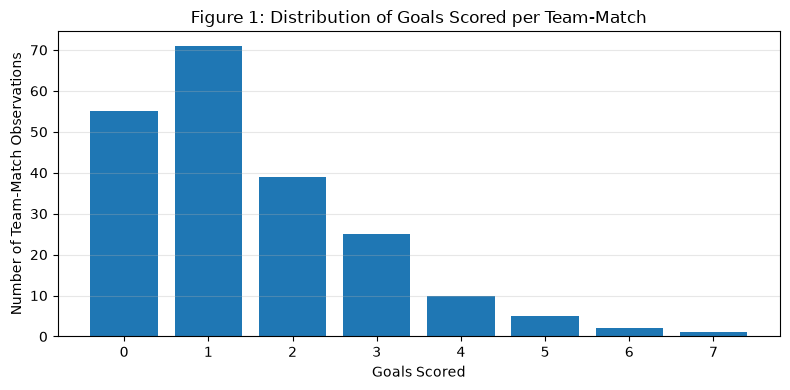

In [3]:

# Step 3: Descriptive statistics and goals distribution

print("Total observations:", len(team_matches))
print("Missing goals:", team_matches["Goals_Scored"].isnull().sum())
print("Duplicate team-match records:",
      team_matches.duplicated(
          subset=["Date", "Team", "Opponent"]
      ).sum())

# Descriptive statistics
display(team_matches["Goals_Scored"].describe().round(2))

# Figure 1: Goals scored by individual teams
goal_counts = team_matches["Goals_Scored"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(goal_counts.index, goal_counts.values)

plt.title("Figure 1: Distribution of Goals Scored per Team-Match")
plt.xlabel("Goals Scored")
plt.ylabel("Number of Team-Match Observations")
plt.xticks(goal_counts.index)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



**Interpretation of Figure 1**

Figure 1 shows how frequently teams scored different numbers of goals in individual matches.

The distribution helps identify common scoring outcomes and unusually high-scoring performances.

All 208 observations are retained for regression preparation.



### 4. Feature Engineering

Eight explanatory variables are created to predict goals scored by an individual team.

The variables describe previous tournament performance, opponent defensive performance, match experience, rest days and host-country advantage.

All historical statistics are calculated using matches played before the current match. The current match result is not used to construct its predictors.

For teams without previous tournament matches, historical values are initially set to zero as neutral placeholders.


In [5]:

# Step 4: Create eight pre-match explanatory variables

# Sort matches by date
team_matches = team_matches.sort_values(
    ["Date"], kind="stable"
).reset_index(drop=True)

# Create match IDs to keep both team records together
team_matches["Match_ID"] = team_matches.apply(
    lambda row: (
        str(row["Date"]) + "|" +
        "|".join(sorted([row["Team"], row["Opponent"]]))
    ),
    axis=1
)

# Host nations
host_nations = {"Canada", "Mexico", "USA"}

# Store previous match information for each team
history = {}

feature_rows = []

# Process each match once, so both teams use pre-match information
for match_id, group in team_matches.groupby(
    "Match_ID", sort=False
):

    current_date = group["Date"].iloc[0]

    # Calculate features before updating histories
    for _, row in group.iterrows():

        team = row["Team"]
        opponent = row["Opponent"]

        previous = history.get(team, [])
        opponent_previous = history.get(opponent, [])

        # Team's previous goals scored
        avg_goals = (
            np.mean([x["GF"] for x in previous])
            if previous else 0
        )

        # Opponent's previous goals conceded
        opponent_avg_conceded = (
            np.mean([x["GA"] for x in opponent_previous])
            if opponent_previous else 0
        )

        # Team's previous clean-sheet rate
        clean_sheet_rate = (
            np.mean([x["GA"] == 0 for x in previous])
            if previous else 0
        )

        # Team's previous scoring rate
        scoring_rate = (
            np.mean([x["GF"] > 0 for x in previous])
            if previous else 0
        )

        # Team's rest days
        rest_days = (
            (current_date - previous[-1]["Date"]).days
            if previous else 0
        )

        # Eight predictors
        feature_rows.append({
            "Match_ID": match_id,
            "Team": team,
            "Prior_Avg_Goals": avg_goals,
            "Opponent_Prior_Avg_Conceded": opponent_avg_conceded,
            "Prior_Clean_Sheet_Rate": clean_sheet_rate,
            "Prior_Scoring_Rate": scoring_rate,
            "Prior_Matches_Played": len(previous),
            "Rest_Days": rest_days,
            "Host_Nation": int(team in host_nations),
            "Home_Indicator": row["Home_Indicator"]
        })

    # Update histories only after features are calculated
    for _, row in group.iterrows():

        history.setdefault(row["Team"], []).append({
            "Date": current_date,
            "GF": row["Goals_Scored"],
            "GA": row["Goals_Conceded"]
        })

# Convert features to a DataFrame
features_2_2 = pd.DataFrame(feature_rows)

print("Total feature records:", len(features_2_2))
print("Number of predictors:", len(features_2_2.columns) - 2)

display(features_2_2.head())


Total feature records: 208
Number of predictors: 8


,Match_ID,Team,Prior_Avg_Goals,Opponent_Prior_Avg_Conceded,Prior_Clean_Sheet_Rate,Prior_Scoring_Rate,Prior_Matches_Played,Rest_Days,Host_Nation,Home_Indicator
0,2026-06-11 00:00:00|Mexico|South Africa,Mexico,0.0,0.0,0.0,0.0,0,0,1,1
1,2026-06-11 00:00:00|Mexico|South Africa,South Africa,0.0,0.0,0.0,0.0,0,0,0,0
2,2026-06-11 00:00:00|Czechia|Korea Republic,Korea Republic,0.0,0.0,0.0,0.0,0,0,0,1
3,2026-06-11 00:00:00|Czechia|Korea Republic,Czechia,0.0,0.0,0.0,0.0,0,0,0,0
4,2026-06-12 00:00:00|Bosnia–Herz|Canada,Canada,0.0,0.0,0.0,0.0,0,0,1,1



### 4.1 Average Goals by Tournament Stage

This analysis compares the average number of goals scored per team-match during the group stage and knockout stage.

The comparison helps identify differences in scoring patterns across tournament stages.


Goals scored by tournament stage:


,Team-Match Observations,Average Goals
Stage,,
Group stage,144,1.49
Knockout stage,64,1.45


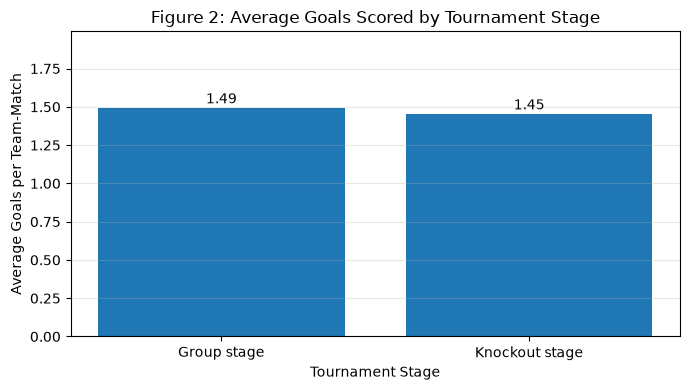

In [7]:

# Figure 2: Average goals scored by tournament stage

# Classify tournament rounds
team_matches["Stage"] = np.where(
    team_matches["Round"] == "Group stage",
    "Group stage",
    "Knockout stage"
)

# Calculate average goals and observation counts
stage_summary = (
    team_matches.groupby("Stage")["Goals_Scored"]
    .agg(["count", "mean"])
    .reindex(["Group stage", "Knockout stage"])
)

stage_summary.columns = [
    "Team-Match Observations",
    "Average Goals"
]

print("Goals scored by tournament stage:")
display(stage_summary.round(2))

# Create Figure 2
plt.figure(figsize=(7, 4))

bars = plt.bar(
    stage_summary.index,
    stage_summary["Average Goals"]
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{bar.get_height():.2f}",
        ha="center"
    )

plt.title("Figure 2: Average Goals Scored by Tournament Stage")
plt.xlabel("Tournament Stage")
plt.ylabel("Average Goals per Team-Match")
plt.ylim(0, stage_summary["Average Goals"].max() + 0.5)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



**Interpretation of Figure 2**

Figure 2 compares average goals scored per team-match between the group stage and knockout stage.

The analysis helps identify whether scoring patterns differ across tournament stages.

The group stage contains more observations than the knockout stage, so the results should be interpreted with consideration of the different sample sizes.



### 4.2 Goals Scored and Goals Conceded

This analysis examines the relationship between goals scored and goals conceded by individual teams.

A scatter plot is used to identify scoring patterns and unusually high-scoring matches.


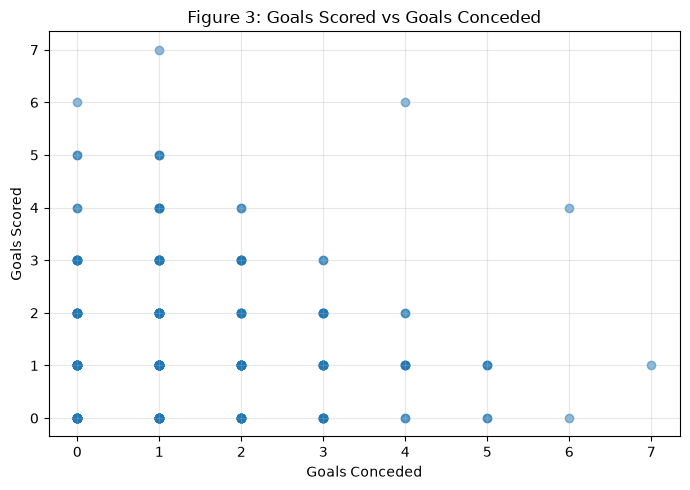

Correlation: -0.11


In [8]:

# Figure 3: Goals scored vs goals conceded

plt.figure(figsize=(7, 5))

plt.scatter(
    team_matches["Goals_Conceded"],
    team_matches["Goals_Scored"],
    alpha=0.5
)

plt.title("Figure 3: Goals Scored vs Goals Conceded")
plt.xlabel("Goals Conceded")
plt.ylabel("Goals Scored")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = team_matches[
    ["Goals_Scored", "Goals_Conceded"]
].corr().iloc[0, 1]

print("Correlation:", round(correlation, 3))



**Interpretation of Figure 3**

Figure 3 shows the relationship between goals scored and goals conceded in individual team-match observations.

The scatter plot helps identify matches with large differences between attacking and defensive outcomes.

Both values describe completed matches and are used for exploratory analysis only. Goals conceded in the current match will not be used as a pre-match predictor.



### 4.3 Previous Match Experience

This figure shows the number of previous World Cup 2026 matches available when predicting each team-match outcome.

It helps identify how much historical information is available for constructing the pre-match explanatory variables.


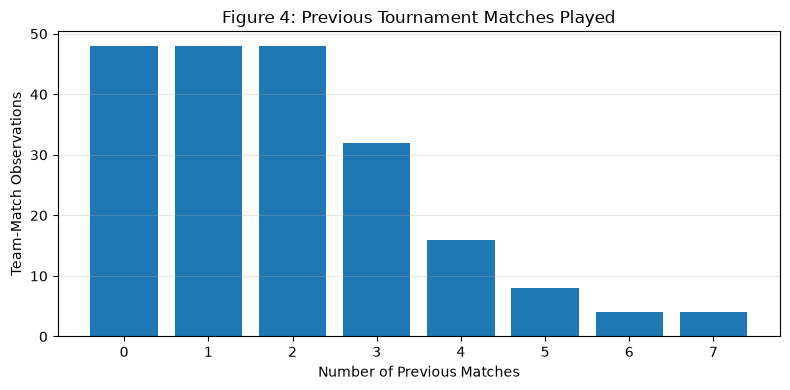

Observations with no previous match: 48


In [11]:

# Figure 4: Previous matches played

experience_counts = (
    features_2_2["Prior_Matches_Played"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 4))

plt.bar(
    experience_counts.index,
    experience_counts.values
)

plt.title("Figure 4: Previous Tournament Matches Played")
plt.xlabel("Number of Previous Matches")
plt.ylabel("Team-Match Observations")
plt.xticks(experience_counts.index)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Observations with no previous match:",
      (features_2_2["Prior_Matches_Played"] == 0).sum())



**Interpretation of Figure 4**

Figure 4 shows how many previous tournament matches were available for each team-match observation.

Teams playing their first match have no previous tournament statistics. Their historical predictor values are therefore represented using neutral placeholders.

This highlights an important limitation of the dataset: predictions for early matches have less historical information than predictions for later matches.



### 5. Final Dataset Validation and Export

The final Regression 2.2 dataset contains 208 team-match observations and eight pre-match explanatory variables.

The dependent variable is Goals_Scored. The dataset is checked for missing values, duplicate observations and the correct number of predictors.

Historical statistics are based on previous matches only. For teams without previous tournament matches, zero is used as a placeholder.

The completed dataset is saved as a CSV file for regression modelling.


In [6]:

# Step 5: Validate and export Regression 2.2 dataset

from pathlib import Path

# Eight explanatory variables
predictors_2_2 = [
    "Prior_Avg_Goals",
    "Opponent_Prior_Avg_Conceded",
    "Prior_Clean_Sheet_Rate",
    "Prior_Scoring_Rate",
    "Prior_Matches_Played",
    "Rest_Days",
    "Host_Nation",
    "Home_Indicator"
]

# Merge using match and team identifiers
final_2_2 = team_matches.merge(
    features_2_2,
    on=["Match_ID", "Team"],
    how="left",
    validate="one_to_one",
    suffixes=("", "_feature")
)

# Select columns for final regression dataset
final_2_2 = final_2_2[
    ["Date", "Round", "Match_ID", "Team", "Opponent",
     "Goals_Scored", "Goals_Conceded"] + predictors_2_2
]

# Validation checks
assert len(final_2_2) == 208
assert len(predictors_2_2) == 8
assert final_2_2["Goals_Scored"].notna().all()
assert final_2_2[predictors_2_2].notna().all().all()

print("Total observations:", len(final_2_2))
print("Number of predictors:", len(predictors_2_2))
print("Missing values:", final_2_2.isnull().sum().sum())
print("Duplicate team-match records:",
      final_2_2.duplicated(["Match_ID", "Team"]).sum())

# Save final dataset
output_folder = Path("../data")
output_folder.mkdir(parents=True, exist_ok=True)

output_path = output_folder / "regression_2_2.csv"
final_2_2.to_csv(output_path, index=False)

print("\nDataset saved successfully!")
print("Location:", output_path)

display(final_2_2.head())


Total observations: 208
Number of predictors: 8
Missing values: 0
Duplicate team-match records: 0

Dataset saved successfully!
Location: ..\data\regression_2_2.csv


,Date,Round,Match_ID,Team,Opponent,Goals_Scored,Goals_Conceded,Prior_Avg_Goals,Opponent_Prior_Avg_Conceded,Prior_Clean_Sheet_Rate,Prior_Scoring_Rate,Prior_Matches_Played,Rest_Days,Host_Nation,Home_Indicator
0,2026-06-11,Group stage,2026-06-11 00:00:00|Mexico|South Africa,Mexico,South Africa,2,0,0.0,0.0,0.0,0.0,0,0,1,1
1,2026-06-11,Group stage,2026-06-11 00:00:00|Czechia|Korea Republic,Korea Republic,Czechia,2,1,0.0,0.0,0.0,0.0,0,0,0,1
2,2026-06-11,Group stage,2026-06-11 00:00:00|Mexico|South Africa,South Africa,Mexico,0,2,0.0,0.0,0.0,0.0,0,0,0,0
3,2026-06-11,Group stage,2026-06-11 00:00:00|Czechia|Korea Republic,Czechia,Korea Republic,1,2,0.0,0.0,0.0,0.0,0,0,0,0
4,2026-06-12,Group stage,2026-06-12 00:00:00|Bosnia–Herz|Canada,Canada,Bosnia–Herz,1,1,0.0,0.0,0.0,0.0,0,0,1,1
